# Fase 7: Optimización del modelo y métrica

En la Fase 6 se compararon siete modelos con validación cruzada y los de *boosting* (LightGBM, XGBoost y CatBoost) quedaron a la cabeza, muy igualados. En esta fase se **optimizan los hiperparámetros** de los mejores candidatos, se **ajusta el umbral de decisión** según el criterio de negocio (priorizar la detección de fallos) y se hace la **evaluación final** sobre el conjunto de test reservado. Por último, se guarda el modelo entrenado para poder desplegarlo.

> **Nota:** CatBoost no se incluye en esta fase porque en el equipo de trabajo una directiva de Control de aplicaciones de Windows bloquea su librería nativa. Como en la Fase 6 quedó por detrás de LightGBM y XGBoost (que estaban prácticamente empatados en primer lugar), la comparación se centra en esos dos.

## 1. Configuración y carga de datos

Se cargan las librerías, el dataset limpio de la Fase 3 y se reproduce **exactamente el mismo split** estratificado 80/20 de la Fase 6 (`random_state=42`), para trabajar sobre los mismos conjuntos de entrenamiento y test.

In [1]:
# Manipulación de datos
import numpy as np
import pandas as pd

# Modelado
import sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             recall_score, precision_score, f1_score, fbeta_score)
import lightgbm as lgb
import xgboost as xgb
import joblib

# Visualización
import matplotlib.pyplot as plt

# Evitamos el ruido de warnings (nombres de features, convergencia, etc.)
import warnings
warnings.filterwarnings("ignore")

# Versiones: son importantes para el despliegue, el modelo guardado debe cargarse con las mismas
import sys
print("Python     :", sys.version.split()[0])
print("scikit-learn:", sklearn.__version__)
print("lightgbm    :", lgb.__version__)
print("xgboost     :", xgb.__version__)

Python     : 3.14.2
scikit-learn: 1.8.0
lightgbm    : 4.6.0
xgboost     : 3.2.0


In [2]:
# Dataset limpio generado en la Fase 3
df_clean = pd.read_csv("../data/ai4i2020_clean.csv")

# X: variables de entrada | y: variable objetivo
X = df_clean.drop(columns=["Machine failure"])
y = df_clean["Machine failure"]

# Mismo split que en la Fase 6: 80/20, estratificado y con la misma semilla
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print(f"Train: {X_train.shape[0]} filas | Test: {X_test.shape[0]} filas")
print(f"Fallos en train: {y_train.mean()*100:.2f} % | Fallos en test: {y_test.mean()*100:.2f} %")

Train: 7984 filas | Test: 1997 filas
Fallos en train: 3.38 % | Fallos en test: 3.41 %


## 2. Preprocesado

Se reutiliza el preprocesado de los modelos de árboles de la Fase 6: las variables numéricas pasan tal cual (los árboles no necesitan escalado) y `Type` se codifica con one-hot. Todo va dentro del `Pipeline`, de modo que en cada partición de la validación cruzada el preprocesado se ajusta **solo** con los datos de entrenamiento de esa partición y no hay fuga de datos.

In [3]:
features_cat = ["Type"]
features_num = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
]

# Preprocesado para modelos de árboles: numéricas passthrough + Type one-hot
preprocessing_trees = ColumnTransformer(
    transformers=[
        ("num", "passthrough", features_num),
        ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), features_cat),
    ],
    remainder="drop",
)

# Desbalanceo: XGBoost usa scale_pos_weight = nº sin fallo / nº con fallo
peso_clases = np.sum(y_train == 0) / np.sum(y_train == 1)

# Validación cruzada estratificada (mantiene la proporción de fallos en cada partición)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print(f"scale_pos_weight (XGBoost): {peso_clases:.1f}")

scale_pos_weight (XGBoost): 28.6


## 3. Optimización de hiperparámetros

Se optimizan **LightGBM** y **XGBoost** con `RandomizedSearchCV`, que prueba combinaciones de hiperparámetros al azar y se queda con la mejor según la validación cruzada.

- **Métrica de optimización: PR-AUC** (`average_precision`). Es la adecuada con clases muy desbalanceadas porque resume el equilibrio entre *precision* y *recall* a lo largo de todos los umbrales, sin depender de uno concreto.
- `n_iter=30`: se prueban 30 combinaciones por modelo.
- El desbalanceo se gestiona con `class_weight="balanced"` (LightGBM) y `scale_pos_weight` (XGBoost).

In [4]:
def optimizar(nombre, estimador, espacio, n_iter=30):
    """Ajusta hiperparámetros con RandomizedSearchCV optimizando PR-AUC."""
    pipe = Pipeline([("prep", preprocessing_trees), ("modelo", estimador)])
    busqueda = RandomizedSearchCV(
        pipe, param_distributions=espacio,
        n_iter=n_iter, scoring="average_precision",
        cv=cv, n_jobs=-1, random_state=42, refit=True,
    )
    busqueda.fit(X_train, y_train)
    print(f"{nombre}: mejor PR-AUC (CV) = {busqueda.best_score_:.4f}")
    print("  Mejores hiperparámetros:")
    for k, v in busqueda.best_params_.items():
        print(f"    {k.replace('modelo__', '')}: {v}")
    return busqueda


# --- LightGBM ---
espacio_lgbm = {
    "modelo__n_estimators": [200, 300, 400, 600, 800],
    "modelo__num_leaves": [15, 31, 63, 127],
    "modelo__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "modelo__max_depth": [-1, 4, 6, 8],
    "modelo__min_child_samples": [10, 20, 30, 50],
    "modelo__colsample_bytree": [0.7, 0.8, 1.0],
    "modelo__reg_lambda": [0, 1, 5],
}
lgbm = lgb.LGBMClassifier(class_weight="balanced", random_state=42, n_jobs=1, verbose=-1)
busqueda_lgbm = optimizar("LightGBM", lgbm, espacio_lgbm)

LightGBM: mejor PR-AUC (CV) = 0.7905
  Mejores hiperparámetros:
    reg_lambda: 5
    num_leaves: 127
    n_estimators: 300
    min_child_samples: 10
    max_depth: -1
    learning_rate: 0.1
    colsample_bytree: 1.0


In [5]:
# --- XGBoost ---
espacio_xgb = {
    "modelo__n_estimators": [200, 300, 400, 600],
    "modelo__max_depth": [3, 4, 6, 8],
    "modelo__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "modelo__subsample": [0.7, 0.8, 1.0],
    "modelo__colsample_bytree": [0.7, 0.8, 1.0],
    "modelo__min_child_weight": [1, 3, 5],
    "modelo__gamma": [0, 1, 5],
    "modelo__reg_lambda": [1, 5, 10],
}
xgboost = xgb.XGBClassifier(
    scale_pos_weight=peso_clases, random_state=42, eval_metric="logloss", n_jobs=1
)
busqueda_xgb = optimizar("XGBoost", xgboost, espacio_xgb)

XGBoost: mejor PR-AUC (CV) = 0.7863
  Mejores hiperparámetros:
    subsample: 1.0
    reg_lambda: 10
    n_estimators: 200
    min_child_weight: 5
    max_depth: 8
    learning_rate: 0.05
    gamma: 0
    colsample_bytree: 1.0


In [6]:
# Comparación: PR-AUC base (Fase 6) vs PR-AUC optimizado
comparativa = pd.DataFrame({
    "modelo": ["LightGBM", "XGBoost"],
    "pr_auc_base_fase6": [0.775, 0.774],
    "pr_auc_optimizado": [busqueda_lgbm.best_score_, busqueda_xgb.best_score_],
}).round(4)
comparativa["mejora"] = (comparativa["pr_auc_optimizado"] - comparativa["pr_auc_base_fase6"]).round(4)
comparativa = comparativa.sort_values("pr_auc_optimizado", ascending=False).reset_index(drop=True)
display(comparativa)

# Nos quedamos con el mejor de los dos
mejor_nombre = comparativa.loc[0, "modelo"]
mejor_busqueda = busqueda_lgbm if mejor_nombre == "LightGBM" else busqueda_xgb
mejor_modelo = mejor_busqueda.best_estimator_   # pipeline ya reentrenado con todo el train
print(f"\nModelo elegido: {mejor_nombre}")

,modelo,pr_auc_base_fase6,pr_auc_optimizado,mejora
0,LightGBM,0.775,0.7905,0.0155
1,XGBoost,0.774,0.7863,0.0123



Modelo elegido: LightGBM


### Conclusión 3: modelo elegido

Se elige el modelo con mayor PR-AUC en validación cruzada tras la optimización. La mejora sobre los valores base de la Fase 6 confirma que el ajuste de hiperparámetros aporta, aunque de forma moderada: los modelos de *boosting* ya partían de un rendimiento alto.

## 4. Ajuste del umbral de decisión

Por defecto, el modelo clasifica como fallo cuando la probabilidad estimada supera 0,5. Pero el criterio de negocio dice que **una parada inesperada es más costosa que un mantenimiento preventivo innecesario**, así que interesa priorizar el **recall** (detectar los fallos reales) aun a costa de algunas falsas alarmas.

Para elegir el umbral se usa la métrica **F2**, que es como la F1 pero dando más peso al recall (el doble). Muy importante: el umbral se elige con **validación cruzada sobre el conjunto de entrenamiento**, nunca sobre el test, para que la evaluación final no quede contaminada.

Umbral óptimo (máximo F2 en CV del train): 0.155
En ese punto (train CV) -> recall: 0.833 | precision: 0.545 | F2: 0.754


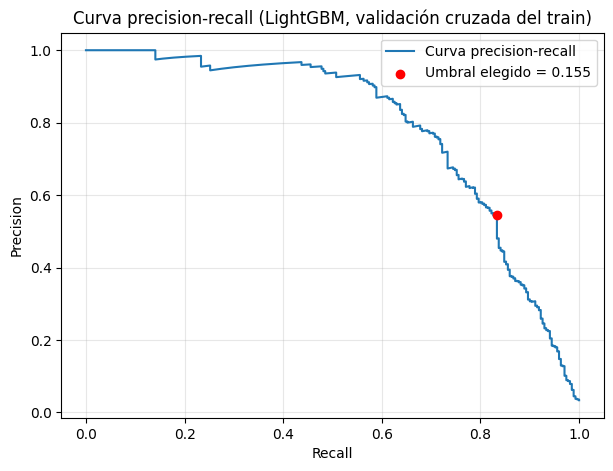

In [7]:
# Probabilidades out-of-fold sobre el TRAIN (cada predicción la hace un modelo que no vio esa fila)
proba_train = cross_val_predict(
    mejor_modelo, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1
)[:, 1]

# Curva precision-recall y F2 para cada umbral
precisiones, recalls, umbrales = precision_recall_curve(y_train, proba_train)
# precision_recall_curve devuelve un umbral menos que puntos; alineamos quitando el último punto
f2 = (1 + 2**2) * (precisiones * recalls) / (2**2 * precisiones + recalls + 1e-12)
idx = np.nanargmax(f2[:-1])
umbral_optimo = umbrales[idx]

print(f"Umbral óptimo (máximo F2 en CV del train): {umbral_optimo:.3f}")
print(f"En ese punto (train CV) -> recall: {recalls[idx]:.3f} | precision: {precisiones[idx]:.3f} | F2: {f2[idx]:.3f}")

# Gráfico de la curva precision-recall con el punto elegido
plt.figure(figsize=(7, 5))
plt.plot(recalls, precisiones, label="Curva precision-recall")
plt.scatter(recalls[idx], precisiones[idx], color="red", zorder=5,
            label=f"Umbral elegido = {umbral_optimo:.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title(f"Curva precision-recall ({mejor_nombre}, validación cruzada del train)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### Conclusión 4: umbral elegido

El umbral que maximiza F2 es menor que el 0,5 por defecto, lo que hace que el modelo marque como fallo más casos y así **recupere más recall**. Es coherente con el objetivo de negocio: preferimos avisar de más y revisar alguna máquina de sobra antes que dejar pasar un fallo real.

## 5. Evaluación final sobre el conjunto de test

Ahora sí se usa el conjunto de test, que no ha intervenido en ningún momento de la optimización ni del ajuste del umbral. Esta es la estimación honesta del rendimiento del modelo con datos nuevos.

In [8]:
# Probabilidades sobre el test (el modelo ya está entrenado con todo el train)
proba_test = mejor_modelo.predict_proba(X_test)[:, 1]

# Aplicamos el umbral elegido
pred_test = (proba_test >= umbral_optimo).astype(int)

# Métricas que no dependen del umbral
pr_auc_test = average_precision_score(y_test, proba_test)
roc_auc_test = roc_auc_score(y_test, proba_test)

# Métricas al umbral elegido
rec = recall_score(y_test, pred_test)
prec = precision_score(y_test, pred_test)
f1 = f1_score(y_test, pred_test)
f2_test = fbeta_score(y_test, pred_test, beta=2)

print(f"Modelo: {mejor_nombre} | Umbral: {umbral_optimo:.3f}\n")
print(f"PR-AUC (test) : {pr_auc_test:.4f}")
print(f"ROC-AUC (test): {roc_auc_test:.4f}\n")
print(f"Recall   : {rec:.3f}")
print(f"Precision: {prec:.3f}")
print(f"F1       : {f1:.3f}")
print(f"F2       : {f2_test:.3f}\n")
print(classification_report(y_test, pred_test, target_names=["No falla", "Falla"]))

Modelo: LightGBM | Umbral: 0.155

PR-AUC (test) : 0.8656
ROC-AUC (test): 0.9714

Recall   : 0.897
Precision: 0.598
F1       : 0.718
F2       : 0.816

              precision    recall  f1-score   support

    No falla       1.00      0.98      0.99      1929
       Falla       0.60      0.90      0.72        68

    accuracy                           0.98      1997
   macro avg       0.80      0.94      0.85      1997
weighted avg       0.98      0.98      0.98      1997



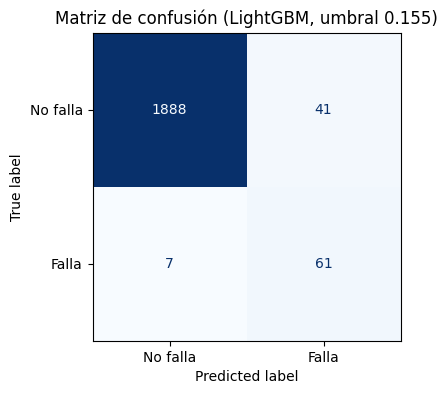

Fallos detectados (verdaderos positivos): 61 de 68
Fallos no detectados (falsos negativos) : 7
Falsas alarmas (falsos positivos)       : 41


In [9]:
# Matriz de confusión
cm = confusion_matrix(y_test, pred_test)
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(cm, display_labels=["No falla", "Falla"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"Matriz de confusión ({mejor_nombre}, umbral {umbral_optimo:.3f})")
plt.show()

vn, fp, fn, vp = cm[0, 0], cm[0, 1], cm[1, 0], cm[1, 1]
print(f"Fallos detectados (verdaderos positivos): {vp} de {vp + fn}")
print(f"Fallos no detectados (falsos negativos) : {fn}")
print(f"Falsas alarmas (falsos positivos)       : {fp}")

### Conclusión 5: rendimiento final

El modelo detecta la gran mayoría de los fallos reales del conjunto de test (recall alto), que es justo lo que pide el negocio. El coste son algunas falsas alarmas (falsos positivos), es decir, mantenimientos preventivos que podrían no haber hecho falta, un coste asumible frente al de una parada no planificada. Los pocos falsos negativos son los casos a seguir vigilando.

## 6. Guardado del modelo para el despliegue

Se guarda el **pipeline completo** (preprocesado + modelo) con `joblib`, de forma que la futura API pueda cargarlo y recibir los datos crudos sin tener que repetir el preprocesado. Junto al modelo se guarda un archivo de metadatos con el umbral de decisión, las features esperadas, las métricas y las versiones de las librerías (imprescindible para que el despliegue cargue el modelo con el mismo entorno).

In [10]:
import json, os
from datetime import date

os.makedirs("../models", exist_ok=True)

ruta_modelo = "../models/modelo_mantenimiento.joblib"
joblib.dump(mejor_modelo, ruta_modelo)

metadatos = {
    "modelo": mejor_nombre,
    "fecha": str(date.today()),
    "umbral_decision": round(float(umbral_optimo), 4),
    "features_entrada": list(X_train.columns),
    "objetivo": "Machine failure",
    "metricas_test": {
        "pr_auc": round(float(pr_auc_test), 4),
        "roc_auc": round(float(roc_auc_test), 4),
        "recall": round(float(rec), 3),
        "precision": round(float(prec), 3),
        "f1": round(float(f1), 3),
        "f2": round(float(f2_test), 3),
    },
    "versiones": {
        "python": sys.version.split()[0],
        "scikit_learn": sklearn.__version__,
        "lightgbm": lgb.__version__,
        "xgboost": xgb.__version__,
    },
}
with open("../models/modelo_mantenimiento_metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadatos, f, indent=2, ensure_ascii=False)

print("Modelo guardado en :", ruta_modelo)
print("Metadatos guardados en: ../models/modelo_mantenimiento_metadata.json")
print(json.dumps(metadatos, indent=2, ensure_ascii=False))

Modelo guardado en : ../models/modelo_mantenimiento.joblib
Metadatos guardados en: ../models/modelo_mantenimiento_metadata.json
{
  "modelo": "LightGBM",
  "fecha": "2026-11-04",
  "umbral_decision": 0.1547,
  "features_entrada": [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
  ],
  "objetivo": "Machine failure",
  "metricas_test": {
    "pr_auc": 0.8656,
    "roc_auc": 0.9714,
    "recall": 0.897,
    "precision": 0.598,
    "f1": 0.718,
    "f2": 0.816
  },
  "versiones": {
    "python": "3.14.2",
    "scikit_learn": "1.8.0",
    "lightgbm": "4.6.0",
    "xgboost": "3.2.0"
  }
}


## 7. Conclusiones y siguientes pasos

- Se optimizaron los hiperparámetros de LightGBM y XGBoost con `RandomizedSearchCV`, usando PR-AUC como métrica por el fuerte desbalanceo de clases.
- Se eligió el mejor modelo y se ajustó su **umbral de decisión** con F2 sobre la validación cruzada del train, priorizando el recall según el criterio de negocio.
- La **evaluación final sobre el test** confirma un buen rendimiento, con la mayoría de los fallos detectados.
- Se guardó el **pipeline completo + metadatos** listos para desplegar.

**Siguientes pasos (despliegue):**
- Construir la API (Flask) que cargue `modelo_mantenimiento.joblib`, reciba las variables de una máquina y devuelva la predicción aplicando el umbral guardado.
- Fijar el entorno de producción con las mismas versiones de librerías recogidas en los metadatos.
- Para producción, se puede reentrenar el pipeline con **todos** los datos (train + test) una vez validado, manteniendo los hiperparámetros y el umbral elegidos.

> **Reproducibilidad:** si se reentrena o se despliega en otra máquina, deben usarse las versiones de librerías registradas en el archivo de metadatos; en particular, el modelo guardado debe cargarse con la misma versión de scikit-learn.